<a href="https://colab.research.google.com/github/nanknee/Major-Project-I-RG-91/blob/main/cropnet_weather_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA: CropNet WRF-HRRR daily weather (Delaware + Louisiana, 2022)


1. Load and structure
2. Data quality
3. Distributions
4. Time patterns
5. Seasonality
6. Spatial coverage
7. Correlations
8. Extremes and anomalies
9. Stress-feature preview
10. Findings

In [ ]:

!pip install cropnet


!pip install ecmwflibs

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.0/9.0 MB 59.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 36.2/36.2 MB 48.6 MB/s  0:00:00
  Created wheel for cropnet: filename=cropnet-0.2.1-py3-none-any.whl size=38963 sha256=1b8e21573b48a56b3ab955b1d82558c8d4318d52bc3f31f999133881db0e55ba
  Stored in directory: /root/.cache/pip/wheels/75/b3/07/b116f0099f3c4ce96f30431c9753c04cc550705a703fecaf36
Successfully built cropnet
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7/7 [cropnet]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 93.4/93.4 MB 53.3 MB/s  0:00:01


In [ ]:
from huggingface_hub import snapshot_download

snapshot_download(
    repo_id="CropNet/CropNet",
    repo_type="dataset",
    local_dir="/content/CropNet",
    allow_patterns=[
        "WRF-HRRR Computed Dataset/data/2022/DE/*",
        "WRF-HRRR Computed Dataset/data/2022/LA/*",
    ],
)

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 24 files:   0%|          | 0/24 [00:00<?, ?it/s]

'/content/CropNet'

In [ ]:
import glob, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
PAL = sns.color_palette("colorblind")
STATE_PAL = {}

DATA_DIR = "/content/CropNet/WRF-HRRR Computed Dataset"
FOCUS_FIPS = [10003, 22007]

## 1. Load and structure

In [ ]:
files = [f for f in glob.glob(os.path.join(DATA_DIR, "**", "*"), recursive=True)
         if f.lower().endswith((".parquet", ".csv"))]
files = sorted(files)
assert files, f"No .parquet/.csv files under {DATA_DIR}. Check the path."
print(len(files), "files, e.g.", os.path.relpath(files[0], DATA_DIR))

def read_any(p):
    return pd.read_parquet(p) if p.lower().endswith(".parquet") else pd.read_csv(p)

raw = pd.concat([read_any(f) for f in files], ignore_index=True)

rename = {
    "Daily/Monthly": "freq", "FIPS Code": "fips", "Grid Index": "grid",
    "Lat (llcrnr)": "lat_ll", "Lon (llcrnr)": "lon_ll", "Lat (urcrnr)": "lat_ur", "Lon (urcrnr)": "lon_ur",
    "Avg Temperature (K)": "t_avg_k", "Max Temperature (K)": "t_max_k", "Min Temperature (K)": "t_min_k",
    "Precipitation (kg m**-2)": "precip_mm", "Relative Humidity (%)": "rh",
    "Wind Gust (m s**-1)": "gust", "Wind Speed (m s**-1)": "wind",
    "U Component of Wind (m s**-1)": "u", "V Component of Wind (m s**-1)": "v",
    "Downward Shortwave Radiation Flux (W m**-2)": "sw_rad", "Vapor Pressure Deficit (kPa)": "vpd",
}
df = raw.rename(columns=rename)
for k in ["t_avg", "t_max", "t_min"]:
    df[k + "_c"] = df[k + "_k"] - 273.15          # Kelvin -> Celsius

METRICS = ["t_avg_c", "t_max_c", "t_min_c", "precip_mm", "rh", "wind", "gust", "u", "v", "sw_rad", "vpd"]
STATE_PAL.update(dict(zip(sorted(df["State"].unique()), PAL)))

print("rows, cols:", df.shape)
print("\nrows per frequency:"); print(df["freq"].value_counts())
print("\nstates / counties / grid cells:")
print(df.groupby("State").agg(counties=("fips", "nunique"), grid_cells=("grid", "nunique"), rows=("fips", "size")))

24 files, e.g. data/2022/DE/HRRR_10_DE_2022-01.csv
rows, cols: (607434, 26)

rows per frequency:
freq
Daily      606630
Monthly       804
Name: count, dtype: int64

states / counties / grid cells:
           counties  grid_cells    rows
State                                  
DELAWARE          3          31   23761
LOUISIANA        64          66  583673


In [ ]:
col_types = pd.DataFrame({
    "column": df.columns,
    "dtype": df.dtypes.astype(str).values,
    "role": ["identifier" if c in ["fips", "County", "State", "grid"] else
             "temporal" if c in ["Year", "Month", "Day"] else
             "dimension" if c == "freq" else
             "geo" if c.startswith(("lat", "lon")) else "metric" for c in df.columns],
})
display(col_types.groupby("role")["column"].apply(list))

daily = df[df["freq"].str.lower().str.startswith("d")].copy()
monthly = df[~df.index.isin(daily.index)].copy()
n_before = len(daily)
daily = daily.dropna(subset=["Day"])
print(f"daily rows: {len(daily):,} (dropped {n_before-len(daily)} with no Day);  monthly rows: {len(monthly):,}")
daily["date"] = pd.to_datetime(dict(year=daily.Year, month=daily.Month, day=daily.Day.astype(int)))
print("date range:", daily["date"].min().date(), "->", daily["date"].max().date())

key = ["Year", "Month", "Day", "fips", "grid"]
print("duplicate (date, county, grid) keys:", daily.duplicated(key).sum())

,column
role,
dimension,[freq]
geo,"[lat_ll, lon_ll, lat_ur, lon_ur]"
identifier,"[State, County, fips, grid]"
metric,"[t_avg_k, t_max_k, t_min_k, precip_mm, rh, gus..."
temporal,"[Year, Month, Day]"


daily rows: 606,630 (dropped 0 with no Day);  monthly rows: 804
date range: 2022-01-01 -> 2022-12-31
duplicate (date, county, grid) keys: 0


### Findings: Step 1, Load and structure
- **Files and size:** 24 CSV files (12 months x 2 states) give 607,434 rows x 26 columns (23 original columns plus the 3 Celsius columns added here).
- **Row types:** 606,630 daily rows and 804 monthly rows. 804 = 67 counties x 12 months, so monthly rows are one per county per month.
- **Coverage:** 67 counties (Delaware 3, Louisiana 64) from 2022-01-01 to 2022-12-31. Louisiana is about 96% of all rows.
- **Grain:** one daily row = one grid cell in one county on one day (606,630 / 365 = 1,662 county-grid cells, about 24.8 per county). There are no duplicate (date, county, grid) keys.
- **Caution:** `grid` is numbered *within* each county. The "grid_cells" column in the table above (31 and 66) is the highest index, not a cell count. Always use `fips` and `grid` together.

## 2. Data quality

In [ ]:
nulls = (daily[METRICS].isna().mean() * 100).round(3).rename("null_%").to_frame()
nulls["status"] = pd.cut(nulls["null_%"], [-1, 1, 5, 20, 101], labels=["complete", "check", "warn", "alert"])
display(nulls.sort_values("null_%", ascending=False))

checks = {
    "t_min > t_avg": (daily.t_min_c > daily.t_avg_c).mean(),
    "t_avg > t_max": (daily.t_avg_c > daily.t_max_c).mean(),
    "rh outside 0-100": ((daily.rh < 0) | (daily.rh > 100)).mean(),
    "negative precip": (daily.precip_mm < 0).mean(),
    "negative VPD": (daily.vpd < 0).mean(),
    "gust < wind speed": (daily.gust < daily.wind).mean(),
    "sw_rad > 1400": (daily.sw_rad > 1400).mean(),
    "temperature outside -40..50 C": ((daily.t_avg_c < -40) | (daily.t_avg_c > 50)).mean(),
}
display((pd.Series(checks) * 100).round(3).rename("% of rows violating").to_frame())

,null_%,status
t_avg_c,0.0,complete
t_max_c,0.0,complete
t_min_c,0.0,complete
precip_mm,0.0,complete
rh,0.0,complete
wind,0.0,complete
gust,0.0,complete
u,0.0,complete
v,0.0,complete
sw_rad,0.0,complete


,% of rows violating
t_min > t_avg,0.00
t_avg > t_max,0.00
rh outside 0-100,0.00
negative precip,0.00
negative VPD,0.00
gust < wind speed,38.85
sw_rad > 1400,85.78
temperature outside -40..50 C,0.00


In [ ]:
# Is sw_rad an instantaneous flux or a daily total? A flux can't exceed ~1400 W/m2.
print(daily["sw_rad"].describe().round(1))
print("share of rows above 1400:", round((daily.sw_rad > 1400).mean() * 100, 1), "%")

# Is Wind Speed the mean of speeds, or the speed of the mean (U,V)?
vec = np.hypot(daily.u, daily.v)
print("\ncorr(wind, sqrt(u^2+v^2)):", round(daily.wind.corr(vec), 3),
      "| mean wind:", round(daily.wind.mean(), 2), "| mean |(u,v)|:", round(vec.mean(), 2))

count    606630.0
mean       4507.3
std        2378.9
min           0.0
25%        2719.0
50%        4692.0
75%        6415.1
max        8935.2
Name: sw_rad, dtype: float64
share of rows above 1400: 85.8 %

corr(wind, sqrt(u^2+v^2)): 0.928 | mean wind: 5.17 | mean |(u,v)|: 4.44


In [ ]:
# 'Monthly' rows agree with the daily rows? (mean vs sum tells you how monthly values are defined)
if len(monthly):
    dm = daily.groupby(["fips", "grid", "Month"]).agg(t_mean=("t_avg_c", "mean"), p_mean=("precip_mm", "mean"),
                                                   p_sum=("precip_mm", "sum")).reset_index()
    mm = monthly.merge(dm, on=["fips", "grid", "Month"])
    print("matched monthly rows:", len(mm))
    print("corr monthly t_avg vs mean of daily t_avg:", round(mm.t_avg_c.corr(mm.t_mean), 3))
    print("corr monthly precip vs SUM of daily precip:", round(mm.precip_mm.corr(mm.p_sum), 3))
    print("corr monthly precip vs MEAN of daily precip:", round(mm.precip_mm.corr(mm.p_mean), 3))

matched monthly rows: 0
corr monthly t_avg vs mean of daily t_avg: nan
corr monthly precip vs SUM of daily precip: nan
corr monthly precip vs MEAN of daily precip: nan


### Findings: Step 2, Data quality
- **Missing values:** none in any weather column.
- **Rules that pass (0% violations):** min <= avg <= max temperature, humidity within 0-100, no negative precipitation or VPD, all temperatures within -40 to 50 C.
- **Rules that fail:** gust < wind speed in **38.85%** of rows; `sw_rad` > 1400 in **85.78%** of rows.
- **Radiation:** values run 0 to 8,935 (median 4,692), so this is not an instantaneous W/m2 flux. It looks like a daily total. *(Inference: confirm in the CropNet documentation.)*
- **Wind:** wind speed correlates 0.93 with sqrt(u^2+v^2) but is larger on average (5.17 vs 4.44). That fits wind speed being a mean of hourly speeds while u and v are mean components. *(Inference.)*
- **Zero-filled days:** gust and `sw_rad` are both exactly 0 in 3.29% of rows. That is exactly 12 of 365 days, so about 12 whole days look zero-filled. *(Inference: verify the dates.)*
- **Monthly vs daily check matched 0 rows, so it tested nothing.** The join used `grid`, but monthly rows are per county. Redo it by aggregating daily rows to county-month and merging on `fips` and `Month`.

## 3. Distributions

In [ ]:
S = daily.sample(min(len(daily), 200_000), random_state=0)
pct = daily[METRICS].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
pct["skew"] = daily[METRICS].skew()
pct["zeros_%"] = (daily[METRICS] == 0).mean() * 100
display(pct.round(2))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew,zeros_%
t_avg_c,606630.0,19.36,8.25,-12.19,-0.24,4.51,13.56,21.34,26.35,29.36,30.86,33.69,-0.67,0.00
t_max_c,606630.0,24.84,8.23,-6.28,4.34,7.82,20.07,26.97,31.06,35.27,37.48,45.52,-0.79,0.00
t_min_c,606630.0,15.08,8.67,-14.95,-5.35,-0.46,8.00,17.30,22.73,25.50,27.18,30.23,-0.57,0.00
precip_mm,606630.0,2.93,9.67,0.00,0.00,0.00,0.00,0.00,0.51,18.97,48.61,261.99,5.93,51.64
rh,606630.0,73.42,12.16,21.30,42.20,51.70,64.90,74.90,82.90,90.80,94.10,99.70,-0.50,0.00
wind,606630.0,5.17,2.39,0.70,1.46,2.04,3.32,4.71,6.61,9.65,11.66,18.04,0.74,0.00
gust,606630.0,5.33,2.79,0.00,0.00,1.98,3.35,4.72,6.96,10.66,13.25,20.35,0.79,3.29
u,606630.0,-0.50,2.85,-12.72,-7.30,-5.14,-2.28,-0.55,1.11,4.21,6.90,14.02,0.17,0.02
v,606630.0,0.64,4.18,-17.86,-9.46,-6.89,-2.00,0.97,3.61,7.12,9.54,15.04,-0.30,0.01
sw_rad,606630.0,4507.28,2378.91,0.00,0.00,182.90,2719.00,4692.00,6415.10,7971.50,8359.90,8935.20,-0.30,3.29


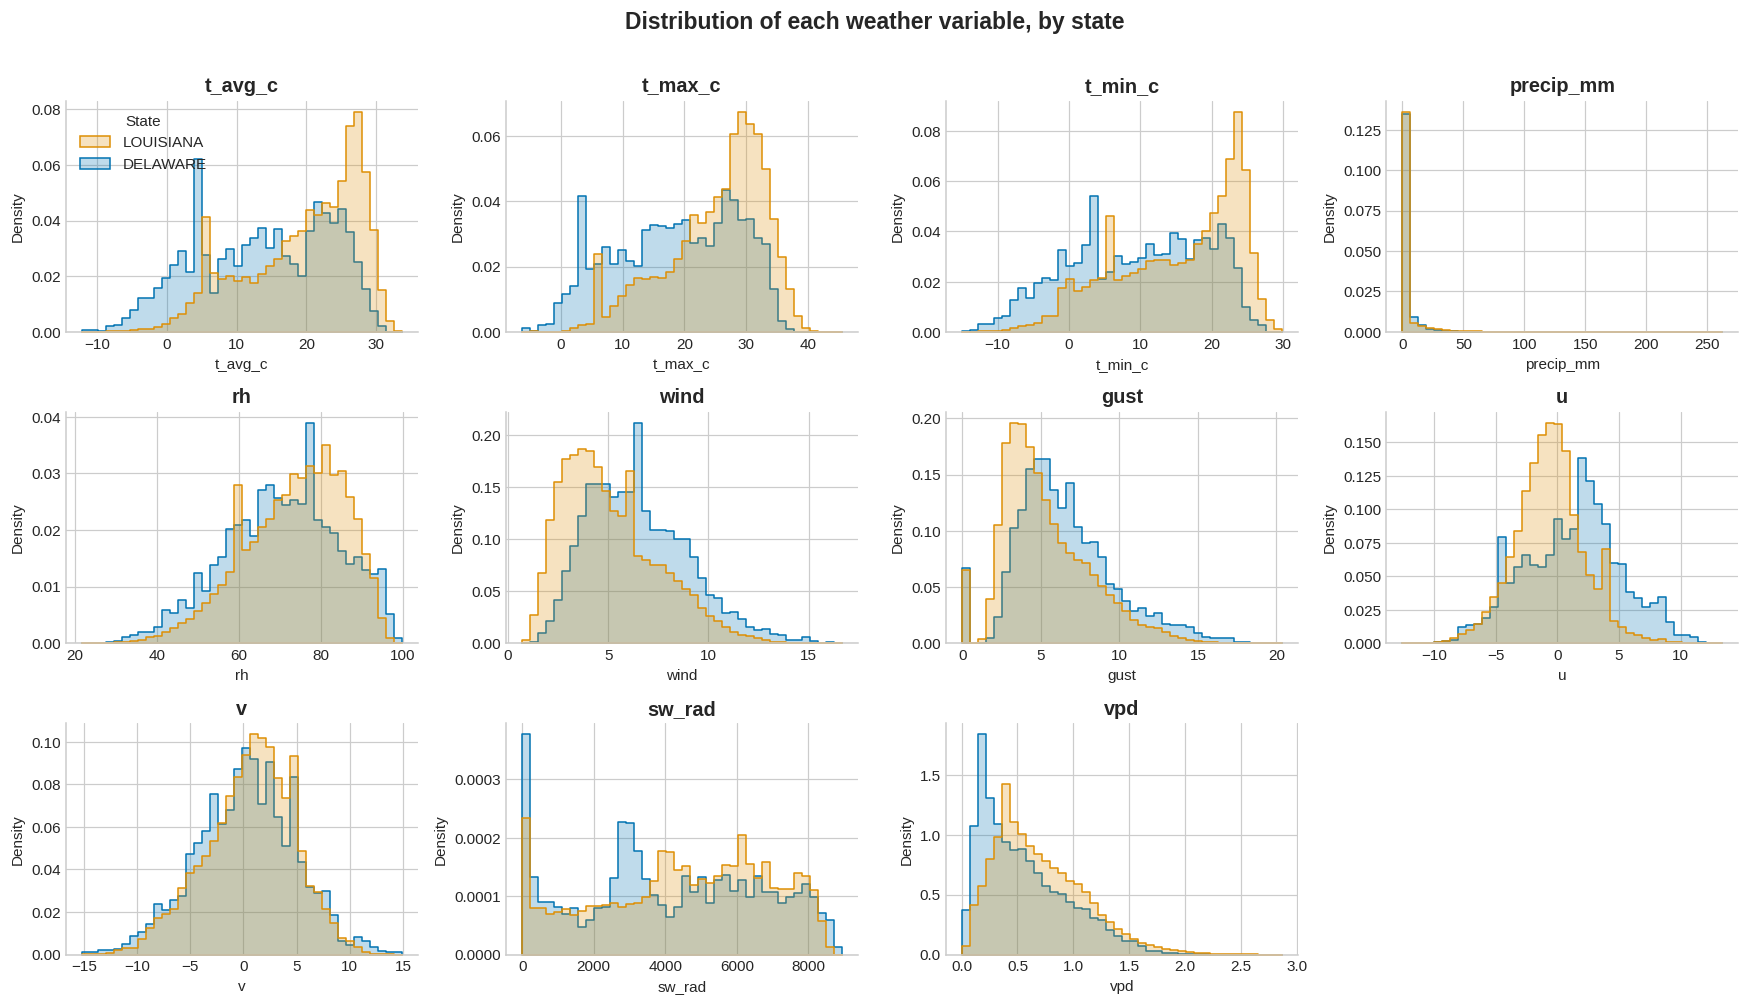

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, c in zip(axes.flat, METRICS):
    sns.histplot(data=S, x=c, hue="State", stat="density", common_norm=False, element="step",
                 bins=40, ax=ax, palette=STATE_PAL, legend=(c == METRICS[0]))
    ax.set_title(c)
for ax in axes.flat[len(METRICS):]:
    ax.set_visible(False)
fig.suptitle("Distribution of each weather variable, by state", y=1.01, fontsize=15, fontweight="bold")
plt.tight_layout(); plt.show()

### Findings: Step 3, Distributions
- Pooled statistics are dominated by Louisiana (about 96% of rows), so they mostly describe Louisiana.
- **Precipitation:** 51.6% of rows are exactly 0; mean 2.9 mm vs median 0; skew 5.9; 95th percentile 19 mm; 99th percentile 49 mm; maximum 262 mm in one cell-day (check this value). Use medians and percentiles, not means.
- **Temperature:** mean avg / max / min of 19.4 / 24.8 / 15.1 C, left-skewed (-0.6 to -0.8). The maximum of 45.5 C sits well above the 99th percentile of 37.5 C, so check the top rows.
- **Humidity and VPD:** relative humidity ranges 21-99.7% (mean 73). VPD is right-skewed (0.84) with mean 0.70, median 0.62 and maximum 2.87 kPa.
- **Wind:** mean 5.2 m/s, maximum 18.

## 4. Time patterns

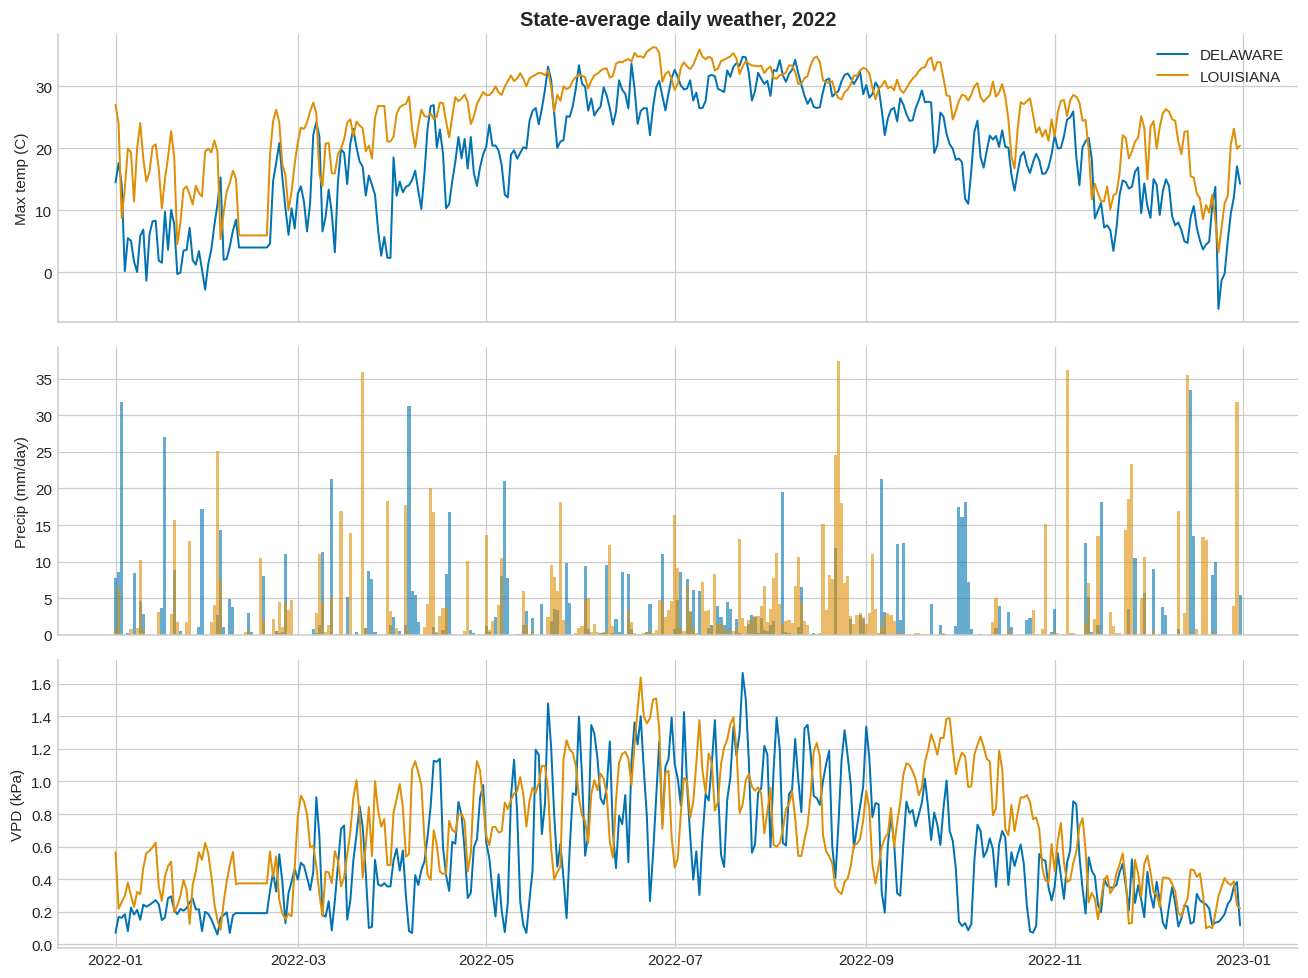

In [ ]:
cd = (daily.groupby(["State", "fips", "County", "date"], as_index=False)[METRICS].mean())   # county-day mean over grid cells
state_day = cd.groupby(["State", "date"])[METRICS].mean().reset_index()

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for st in state_day.State.unique():
    s = state_day[state_day.State == st]
    axes[0].plot(s.date, s.t_max_c, color=STATE_PAL[st], label=st, lw=1.3)
    axes[1].bar(s.date, s.precip_mm, color=STATE_PAL[st], alpha=.6, width=1.0, label=st)
    axes[2].plot(s.date, s.vpd, color=STATE_PAL[st], lw=1.3, label=st)
axes[0].set_ylabel("Max temp (C)"); axes[1].set_ylabel("Precip (mm/day)"); axes[2].set_ylabel("VPD (kPa)")
axes[0].legend(); axes[0].set_title("State-average daily weather, 2022")
plt.tight_layout(); plt.show()

expected days: 365
count     67.0
mean     365.0
std        0.0
min      365.0
25%      365.0
50%      365.0
75%      365.0
max      365.0
Name: date, dtype: float64
counties with missing days: 0


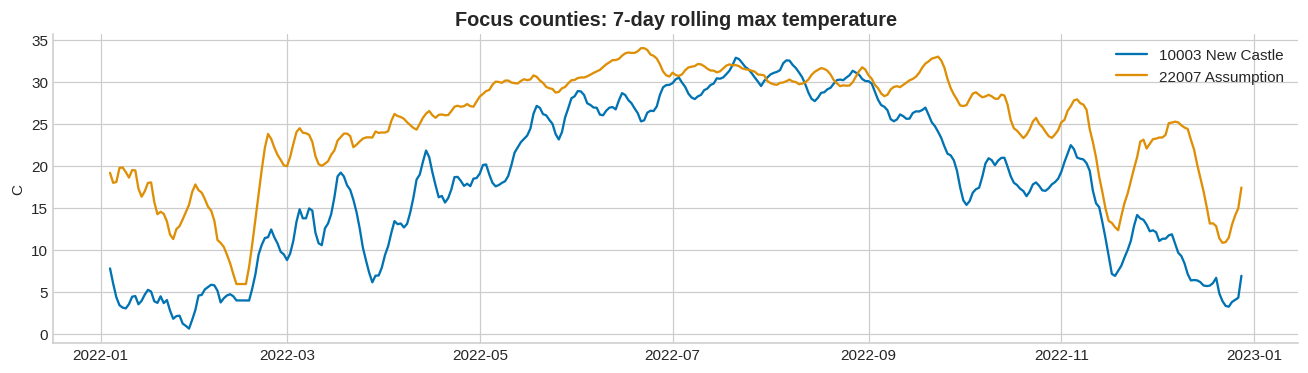

In [ ]:
# Completeness: does every county have every day?
days_expected = daily["date"].nunique()
per_county = cd.groupby("fips")["date"].nunique()
print("expected days:", days_expected)
print(per_county.describe().round(1))
print("counties with missing days:", int((per_county < days_expected).sum()))

foc = cd[cd.fips.isin(FOCUS_FIPS)]
fig, ax = plt.subplots(figsize=(12, 3.5))
for i, (f, g) in enumerate(foc.groupby("fips")):
    ax.plot(g.date, g.t_max_c.rolling(7, center=True).mean(), color=PAL[i], label=f"{f} {g.County.iloc[0].title()}")
ax.set_title("Focus counties: 7-day rolling max temperature"); ax.set_ylabel("C"); ax.legend()
plt.tight_layout(); plt.show()

### Findings: Step 4, Time patterns
- Both states peak in summer. Louisiana is warmer in spring and autumn, and Delaware's summer maxima come close to Louisiana's.
- **Coverage:** all 67 counties have all 365 days, with no missing dates.
- **Suspicious flat stretch:** for roughly three weeks in February, max temperature, VPD and rainfall are flat in both states (read from the chart). Real weather does not do that, so this is likely missing data filled with a constant. *(Inference: find the exact dates.)*
- Rain arrives in bursts, and VPD is highest on hot, dry days (peak June-July).
- **Lesson:** complete dates do not guarantee valid values.

## 5. Seasonality

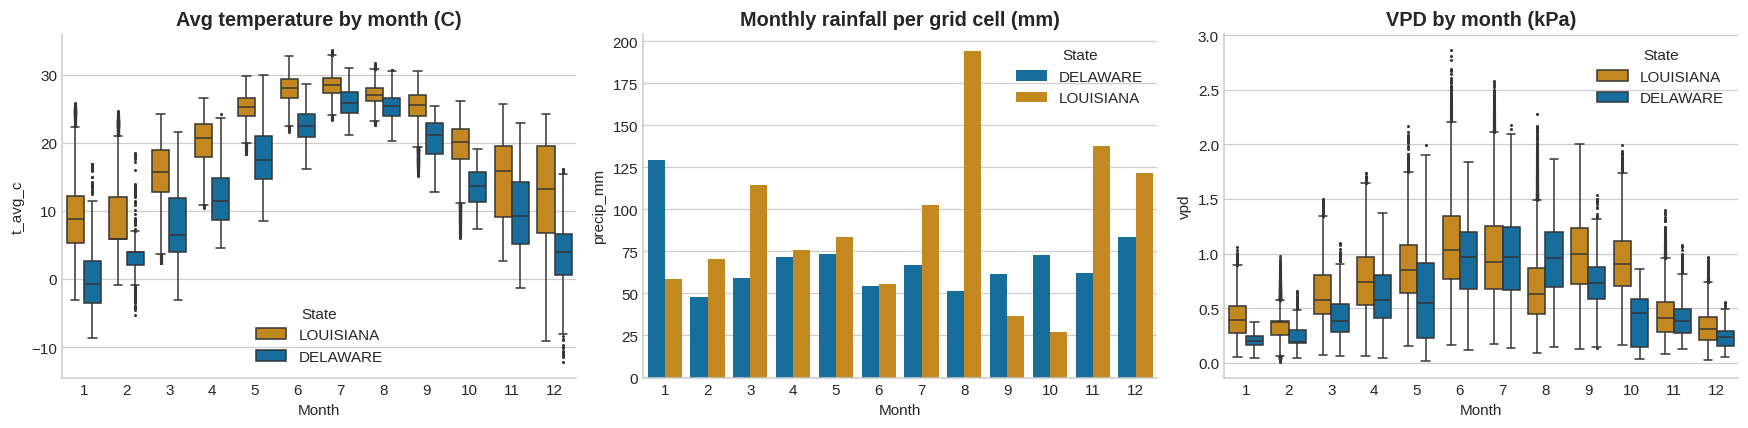

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(data=S, x="Month", y="t_avg_c", hue="State", ax=axes[0], palette=STATE_PAL, fliersize=1)
axes[0].set_title("Avg temperature by month (C)")
mp = (daily.groupby(["State", "fips", "grid", "Month"])["precip_mm"].sum().groupby(["State", "Month"]).mean().reset_index())
sns.barplot(data=mp, x="Month", y="precip_mm", hue="State", ax=axes[1], palette=STATE_PAL)
axes[1].set_title("Monthly rainfall per grid cell (mm)")
sns.boxplot(data=S, x="Month", y="vpd", hue="State", ax=axes[2], palette=STATE_PAL, fliersize=1)
axes[2].set_title("VPD by month (kPa)")
plt.tight_layout(); plt.show()

### Findings: Step 5, Seasonality
- **Temperature:** Louisiana is warmer in every month. Delaware's February box collapses to a narrow band, consistent with the flat stretch in Step 4.
- **Rain per grid cell:** Delaware peaks in January (about 129 mm). Louisiana peaks in August (about 194 mm), with more in November (about 137), December (about 122) and March (about 114). Louisiana is driest in October (about 27 mm) and September (about 36 mm).
- **VPD:** peaks in June-July in both states (medians about 1.0) and is lowest in January-February. Louisiana's June tail reaches about 2.9 kPa. Louisiana's September-October VPD stays high (about 0.9-1.0) while rain is low, which marks an autumn dry-air period.

## 6. Spatial coverage

grid cells per county:
count    67.0
mean     24.8
std      13.6
min       6.0
25%      14.0
50%      21.0
75%      31.5
max      66.0
Name: grid, dtype: float64


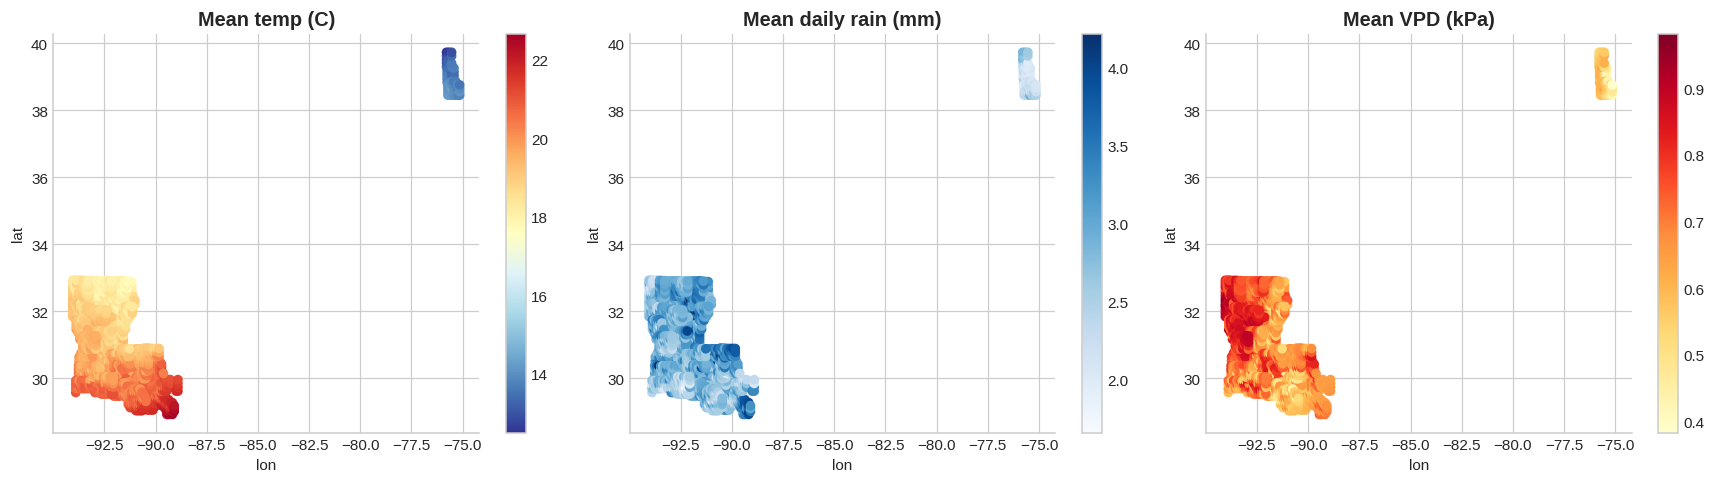

In [ ]:
g = daily.groupby("fips")["grid"].nunique()
print("grid cells per county:"); print(g.describe().round(1))

cells = (daily.groupby(["State", "fips", "grid", "lat_ll", "lon_ll"], as_index=False)
         [["t_avg_c", "precip_mm", "vpd"]].mean())
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (c, cmap, t) in zip(axes, [("t_avg_c", "RdYlBu_r", "Mean temp (C)"),
                                    ("precip_mm", "Blues", "Mean daily rain (mm)"),
                                    ("vpd", "YlOrRd", "Mean VPD (kPa)")]):
    sc = ax.scatter(cells.lon_ll, cells.lat_ll, c=cells[c], cmap=cmap, s=40, edgecolor="none")
    ax.set_title(t); ax.set_xlabel("lon"); ax.set_ylabel("lat"); plt.colorbar(sc, ax=ax)
plt.tight_layout(); plt.show()

### Findings: Step 6, Spatial coverage
- **Grid cells per county:** 6 to 66 (mean 24.8, median 21), so larger counties have more cells.
- **Louisiana:** warmer toward the south (mean up to about 22 C), wettest near the southeast coast (up to about 4 mm/day), highest VPD in the northwest (about 0.9) and lowest in the southeast.
- **Delaware:** cooler (about 12-15 C mean), drier (about 2-2.5 mm/day) and lower VPD (about 0.4-0.6).
- **Implication:** weather varies a lot within a state, so use county-level features, not state averages.

## 7. Correlations

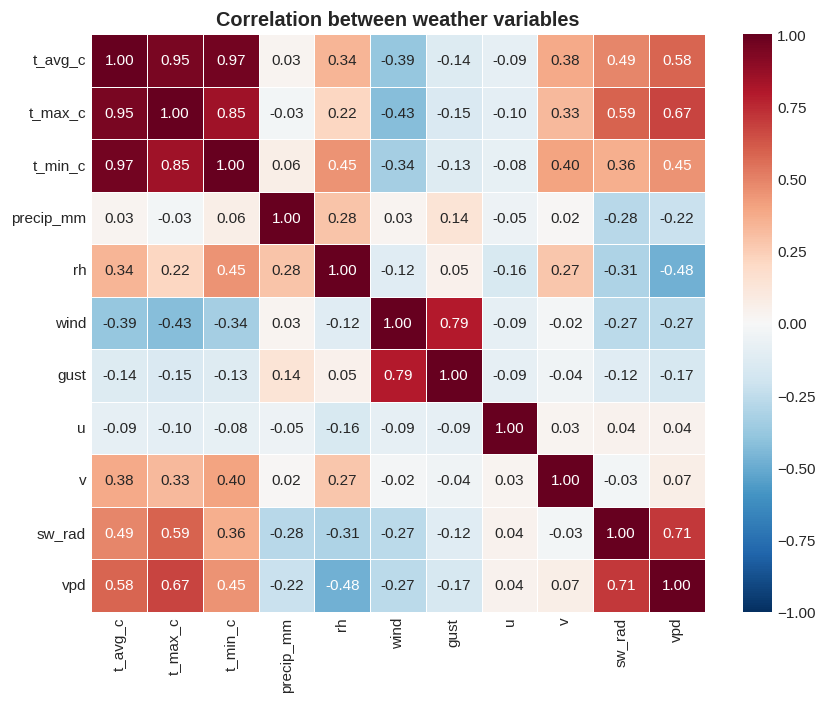

pairs with |r| > 0.7 (candidates for redundancy):


,var_1,var_2,r
1,t_avg_c,t_min_c,0.97
0,t_avg_c,t_max_c,0.95
10,t_max_c,t_min_c,0.85
40,wind,gust,0.79
54,sw_rad,vpd,0.71


In [ ]:
corr = S[METRICS].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=.5, ax=ax)
ax.set_title("Correlation between weather variables"); plt.tight_layout(); plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
upper.index.name, upper.columns.name = "var_1", "var_2"
pairs = (upper.stack().rename("r").reset_index()
         .query("abs(r) > 0.7").sort_values("r", key=abs, ascending=False))
print("pairs with |r| > 0.7 (candidates for redundancy):"); display(pairs.round(2))

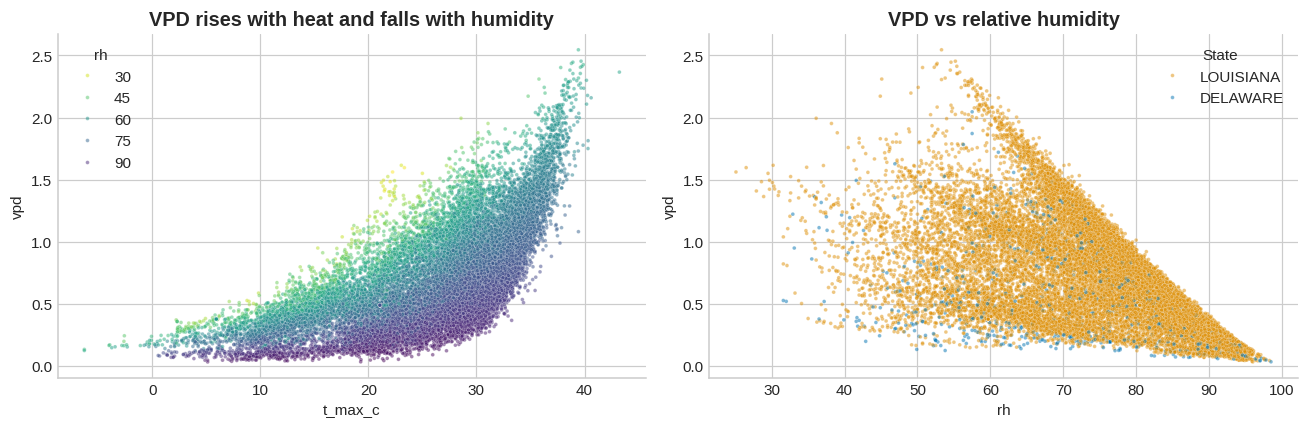

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
Sm = S.sample(min(len(S), 20_000), random_state=0)
sns.scatterplot(data=Sm, x="t_max_c", y="vpd", hue="rh", palette="viridis_r", s=6, alpha=.5, ax=axes[0])
axes[0].set_title("VPD rises with heat and falls with humidity")
sns.scatterplot(data=Sm, x="rh", y="vpd", hue="State", palette=STATE_PAL, s=6, alpha=.5, ax=axes[1])
axes[1].set_title("VPD vs relative humidity")
plt.tight_layout(); plt.show()

**What to look for:** three temperature columns will correlate near 1, so keep one or two. VPD is largely derived from temperature and humidity, so it adds less independent information than it seems. Correlation does not imply causation.

### Findings: Step 7, Correlations
Pairs with |r| > 0.7: `t_avg`-`t_min` 0.97, `t_avg`-`t_max` 0.95, `t_max`-`t_min` 0.85, `wind`-`gust` 0.79, `sw_rad`-`vpd` 0.71.
- **Temperature:** the three columns are nearly redundant, so keep two (for example max and min).
- **Gust:** it correlates with wind and also has quality problems (Step 2), so it is a candidate to drop.
- **Radiation and VPD:** sunny days are dry-air days, so the link is physically sensible.
- **VPD:** no correlation above 0.7 with any single temperature or humidity column, so it is not a copy of them.
- Correlation does not imply causation.

## 8. Extremes and anomalies

In [ ]:
def longest_run(mask):
    best = cur = 0
    for x in mask:
        cur = cur + 1 if x else 0
        best = max(best, cur)
    return best

cd = cd.sort_values(["fips", "date"]).copy()
cd["month"] = cd.date.dt.month
grp = cd.groupby(["fips", "month"])["t_max_c"]
cd["t_max_z"] = (cd.t_max_c - grp.transform("mean")) / grp.transform("std")

summary = cd.groupby(["State", "fips", "County"]).agg(
    hot_days_35C=("t_max_c", lambda s: int((s >= 35).sum())),
    frost_days=("t_min_c", lambda s: int((s <= 0).sum())),
    heavy_rain_days_25mm=("precip_mm", lambda s: int((s >= 25.4).sum())),
    total_rain_mm=("precip_mm", "sum"),
).reset_index()
summary["longest_dry_spell_days"] = [longest_run(g.precip_mm.lt(1).values) for _, g in cd.groupby("fips")]
display(summary[summary.fips.isin(FOCUS_FIPS)])
display(summary.groupby("State")[["hot_days_35C", "frost_days", "heavy_rain_days_25mm", "total_rain_mm", "longest_dry_spell_days"]].describe().T.round(1))

,State,fips,County,hot_days_35C,frost_days,heavy_rain_days_25mm,total_rain_mm,longest_dry_spell_days
1,DELAWARE,10003,NEW CASTLE,0,74,4,904.045357,14
6,LOUISIANA,22007,ASSUMPTION,0,10,6,1092.325000,23


State                         DELAWARE  LOUISIANA
hot_days_35C           count       3.0       64.0
                       mean        1.0       18.7
                       std         1.0       19.4
                       min         0.0        0.0
                       25%         0.5        3.0
                       50%         1.0        9.5
                       75%         1.5       34.5
                       max         2.0       60.0
frost_days             count       3.0       64.0
                       mean       69.7       21.0
                       std         3.8       10.9
                       min        67.0        2.0
                       25%        67.5       11.8
                       50%        68.0       21.0
                       75%        71.0       32.0
                       max        74.0       36.0
heavy_rain_days_25mm   count       3.0       64.0
                       mean        4.3       11.0
                       std         0.6        3.0
                       min         4.0        4.0
                       25%         4.0        9.0
                       50%         4.0       11.0
                       75%         4.5       13.0
                       max         5.0       17.0
total_rain_mm          count       3.0       64.0
                       mean      840.5     1095.7
                       std        63.6       90.9
                       min       776.9      870.3
                       25%       808.7     1029.6
                       50%       840.5     1093.8
                       75%       872.3     1155.4
                       max       904.0     1284.1
longest_dry_spell_days count       3.0       64.0
                       mean       11.7       29.4
                       std         2.1        7.7
                       min        10.0       14.0
                       25%        10.5       23.0
                       50%        11.0       32.0
                       75%        12.5       34.0
                       max        14.0       47.0

In [ ]:
print("days with |z| > 3 for max temp (vs the county's own month):", int((cd.t_max_z.abs() > 3).sum()))
display(cd.loc[cd.t_max_z.abs().sort_values(ascending=False).index[:10],
               ["State", "County", "date", "t_max_c", "t_max_z"]].round({"t_max_c": 2, "t_max_z": 2}))

days with |z| > 3 for max temp (vs the county's own month): 62


,State,County,date,t_max_c,t_max_z
5291,LOUISIANA,CAMERON,2022-07-01,26.97,-4.28
2736,LOUISIANA,AVOYELLES,2022-07-01,26.99,-3.90
11861,LOUISIANA,LA SALLE,2022-07-01,26.98,-3.65
21716,LOUISIANA,VERMILION,2022-07-01,27.57,-3.64
4561,LOUISIANA,CALCASIEU,2022-07-01,27.08,-3.62
6386,LOUISIANA,CONCORDIA,2022-07-01,28.22,-3.62
5656,LOUISIANA,CATAHOULA,2022-07-01,28.06,-3.60
14417,LOUISIANA,OUACHITA,2022-07-02,28.57,-3.54
14671,LOUISIANA,PLAQUEMINES,2022-03-13,14.75,-3.53
15511,LOUISIANA,RAPIDES,2022-07-01,27.94,-3.51


### Findings: Step 8, Extremes and anomalies
| Focus county | Hot days (>=35 C) | Frost days | Heavy-rain days (>=25.4 mm) | Total rain | Longest dry spell |
|---|---|---|---|---|---|
| New Castle, DE (10003) | 0 | 74 | 4 | 904 mm | 14 days |
| Assumption, LA (22007) | 0 | 10 | 6 | 1,092 mm | 23 days |

- **Louisiana overall:** hot days range 0-60 per county (mean 18.7), and the longest dry spell averages 29.4 days. Delaware averages about 1 hot day.
- **Anomalies:** 62 county-days have |z| > 3 for max temperature, about 0.25% of 24,455. The most extreme are cool days around 1-2 July in Louisiana (max temp about 27 C). Check the rainfall on those dates.
- **Caveat:** with one year of data, anomalies are measured against each county's own month in 2022, a weak baseline.

## 9. Stress-feature preview

,fips,County,month,hot_days,rain_mm,mean_vpd,max_vpd,dry_spell
0,10003,NEW CASTLE,1,0,99.79,0.21,0.30,7
1,10003,NEW CASTLE,2,0,60.55,0.23,0.58,4
2,10003,NEW CASTLE,3,0,62.26,0.42,0.83,6
3,10003,NEW CASTLE,4,0,100.58,0.59,1.22,11
4,10003,NEW CASTLE,5,0,88.94,0.65,1.36,4
5,10003,NEW CASTLE,6,0,78.44,0.94,1.46,6
6,10003,NEW CASTLE,7,0,83.41,0.97,1.68,9
7,10003,NEW CASTLE,8,0,42.14,1.01,1.51,10
8,10003,NEW CASTLE,9,0,51.79,0.76,1.40,8
9,10003,NEW CASTLE,10,0,75.95,0.44,0.77,7


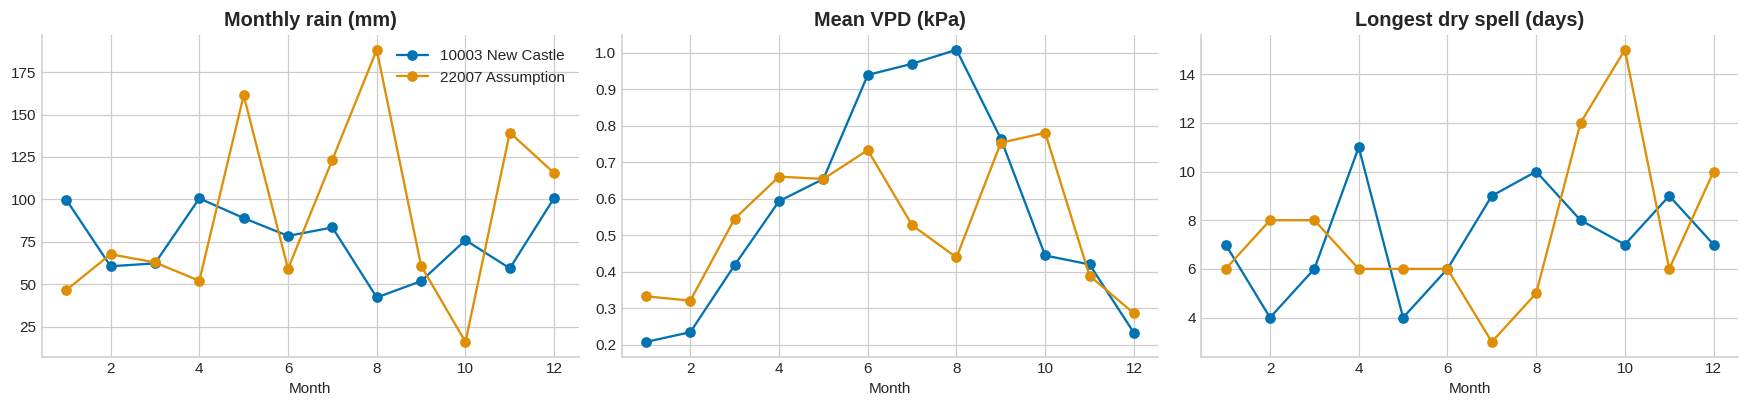

In [ ]:
foc = cd[cd.fips.isin(FOCUS_FIPS)].copy()
feat = foc.groupby(["fips", "County", "month"]).agg(
    hot_days=("t_max_c", lambda s: int((s >= 35).sum())),
    rain_mm=("precip_mm", "sum"),
    mean_vpd=("vpd", "mean"),
    max_vpd=("vpd", "max"),
    dry_spell=("precip_mm", lambda s: longest_run(s.lt(1).values)),
).reset_index()
display(feat.round(2).head(24))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for i, (f, g) in enumerate(feat.groupby("fips")):
    lab = f"{f} {g.County.iloc[0].title()}"
    axes[0].plot(g.month, g.rain_mm, marker="o", color=PAL[i], label=lab)
    axes[1].plot(g.month, g.mean_vpd, marker="o", color=PAL[i], label=lab)
    axes[2].plot(g.month, g.dry_spell, marker="o", color=PAL[i], label=lab)
for ax, t in zip(axes, ["Monthly rain (mm)", "Mean VPD (kPa)", "Longest dry spell (days)"]):
    ax.set_title(t); ax.set_xlabel("Month")
axes[0].legend(); plt.tight_layout(); plt.show()

### Findings: Step 9, Stress-feature preview
- **`hot_days` is 0 in every month for both counties.** A feature with no variance carries no information. Use a lower threshold (for example 32 C) or a percentile-based one.
- **Assumption, LA:** very wet May (161 mm), August (188 mm) and November (139 mm), then a dry October (16 mm) with a 15-day dry spell and mean VPD 0.78. That is the clearest dry-stress signal in the two counties. Its mean VPD peaks in autumn, not summer.
- **New Castle, DE:** August is the driest summer month (42 mm) with mean VPD about 1.0, a maximum VPD of 1.51 and a 10-day dry spell. Its maximum VPD is highest in July (1.68).
- **Rain, VPD and dry-spell length** all vary by month and differ between the two counties, so they are usable weather-branch features.

## 10. Findings

Summary of the EDA on the CropNet WRF-HRRR daily weather data (Delaware and Louisiana, 2022).

**What the data is:** 606,630 daily rows (one per grid cell, county and day) plus 804 county-month rows, covering 67 counties and all 365 days of 2022 with no missing values.

**Data issues to report**

| Issue | Evidence | Treatment |
|---|---|---|
| Flat stretch in February | Flat max temperature, VPD and rain in both states (Step 4) | Likely filled values: treat as missing after confirming dates |
| About 12 zero-filled days | Gust and `sw_rad` are exactly 0 in 3.29% of rows | Treat as missing after confirming dates |
| Gust below wind speed | 38.85% of rows | Drop gust or use with caution |
| Radiation units | 85.78% of values above 1,400; median 4,692 | Treat as a daily total (confirm in documentation) |
| Monthly rows are county-level | 804 = 67 x 12; join on grid matched 0 rows | Compare on county and month |
| Grid index is county-local | State-level distinct counts (31 and 66) are not cell counts | Always use `fips` and `grid` together |
| Precipitation extremes | 51.6% zeros, skew 5.9, maximum 262 mm | Use medians and percentiles; check the top rows |

**Patterns**
- Both states peak in summer; Louisiana is warmer and wetter overall, with more hot days and longer dry spells.
- Weather varies strongly across a state, so use county-level features.
- Redundant columns: the three temperature variables (keep two) and gust.
- Most useful features for stress: monthly rain, mean and maximum VPD, and dry-spell length. `hot_days` at 35 C has no variance in the two focus counties.

**Still to verify**
1. Find the exact flat-stretch dates (days where the state-mean max temperature equals the previous day).
2. Find the zero-radiation dates and check whether they fall inside that stretch.
3. Redo the monthly-vs-daily check on county and month (sum vs mean for precipitation).
4. Check the top rows for temperature (45.5 C) and precipitation (262 mm).

**Limits:** one year and two states only, and these are weather features without stress labels. The labels come from the USDA yield data.

**Next steps:** clean the flagged days, rebuild the monthly features, then add Sentinel-2 NDVI for the same counties and join on county and year.